# Pass-interception survival model

**Analytical question:** Assess a hypothetical passing option.

**Stages in this notebook:** Ball path and timing; player arrival; interception hazard; survival integration.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


#### Helper: `sigmoid`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [4]:
def sigmoid(z):
    return 1/(1+np.exp(-np.clip(z,-40,40)))

In [5]:
X,Y=np.meshgrid(np.linspace(-52.5,52.5,70),np.linspace(-34,34,46))
targets=np.stack([X,Y],axis=-1)
nodes=snapshot.reset_index(drop=True)
positions=nodes[['x','y']].to_numpy()
home=nodes.team_id.eq(1802).to_numpy()
previous=observed[observed.frame_id.eq(frame_id-1)][['player_id','x','y','seconds']]
nodes=nodes.merge(previous,on='player_id',suffixes=('','_previous'),how='left')
dt=nodes.seconds-nodes.seconds_previous
velocity=(nodes[['x','y']].to_numpy()-nodes[['x_previous','y_previous']].to_numpy())/dt.to_numpy()[:,None]
velocity=np.nan_to_num(velocity,nan=0.,posinf=0.,neginf=0.)

## Arrival time and pass-interception survival
Start with reaction plus travel time to each target. Then sample a hypothetical pass path, compare player arrival with ball arrival, and integrate interception hazards. The expected receiver and passer are specified. This is our simplified constant-speed hazard model, not exact Spearman or the `accessible-space` implementation. Parameters need fitting and calibration against real passes.

In [6]:
reaction=.7
player_speed=5.
arrival=reaction+np.linalg.norm(targets[:,:,None,:]-(positions+.7*velocity),axis=-1)/player_speed
control=sigmoid((arrival[:,:,~home].min(axis=-1)-arrival[:,:,home].min(axis=-1))/.45)

#### Helper: `pass_survival`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [7]:
def pass_survival(start,end,defender_positions,ball_speed=15.,reaction=.7,run_speed=5.,rate=2.):
    duration=np.linalg.norm(end-start)/ball_speed
    if duration<1e-9:return 1.
    times=np.linspace(0,duration,40);path=start+(end-start)*times[:,None]/duration
    arrival=reaction+np.linalg.norm(path[:,None,:]-defender_positions[None,:,:],axis=-1)/run_speed
    hazards=rate*sigmoid((times[:,None]-arrival)/.15)
    # Probability of no defender interception under this independent-hazard approximation.
    return float(np.exp(-np.trapezoid(hazards.sum(axis=1),times)))

,player_id,completion_proxy
1,287934,0.997385
3,50999,0.998806
4,51002,0.999949
5,51043,0.993757
6,51050,0.999493
8,560882,0.999895
9,560983,0.999853
12,560986,0.977163
16,795537,0.808715
17,797298,0.978780


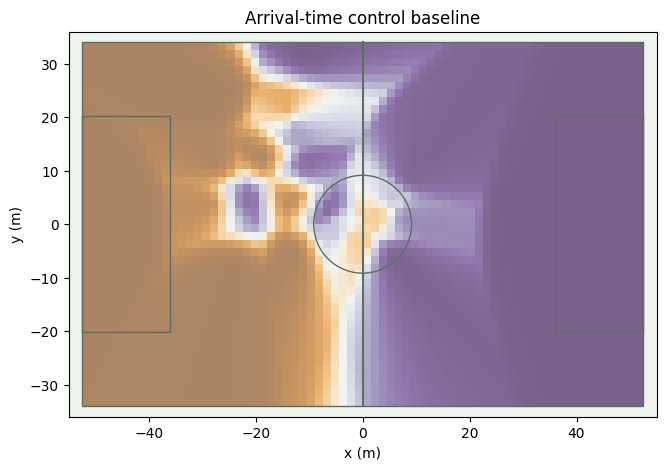

In [8]:
ball=wide[wide.frame_id.eq(frame_id)].iloc[0]
start=np.array([ball.ball_x,ball.ball_y])
options=nodes[nodes.team_id.eq(1802)].copy()
options['completion_proxy']=[pass_survival(start,np.array([r.x,r.y]),positions[~home]) for r in options.itertuples()]
display(options[['player_id','completion_proxy']])
assert options.completion_proxy.between(0,1).all()
plt.figure(figsize=(8,5))
pitch(plt.gca())
plt.imshow(control,origin='lower',extent=(-52.5,52.5,-34,34),alpha=.6,cmap='PuOr',vmin=0,vmax=1)
plt.title('Arrival-time control baseline')
plt.show()

### Intermediate steps: Expose ball travel, player arrival and interception hazard

A pass is hypothetical here. The final survival score is the end of a sequence of local hazard calculations, not a trained completion probability.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `interception_components`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def interception_components(start,end,defenders,ball_speed=15.,reaction=.7,run_speed=5.,rate=2.):
    duration=np.linalg.norm(end-start)/ball_speed
    times=np.linspace(0,max(duration,1e-6),40)
    path=start+(end-start)*np.linspace(0,1,40)[:,None]
    player_arrival=reaction+np.linalg.norm(path[:,None,:]-defenders[None,:,:],axis=-1)/run_speed
    hazard=rate*sigmoid((times[:,None]-player_arrival)/.15)
    increments=(hazard.sum(axis=1)[1:]+hazard.sum(axis=1)[:-1])/2*np.diff(times)
    survival=np.exp(-np.r_[0,np.cumsum(increments)])
    return times,player_arrival,hazard,survival

,ball_time_s,earliest_defender_arrival_s,total_hazard_per_s,survival
0,0.000000,1.218802,0.000592,1.000000
1,0.060767,1.101081,0.001944,0.999923
2,0.121533,1.045026,0.004230,0.999735
3,0.182300,1.079059,0.005053,0.999453
4,0.243067,1.184557,0.003753,0.999186
5,0.303833,1.326396,0.002187,0.999006
6,0.364600,1.485121,0.001139,0.998905
7,0.425367,1.652326,0.000560,0.998853
8,0.486134,1.824234,0.000267,0.998828
9,0.546900,1.998978,0.000125,0.998816


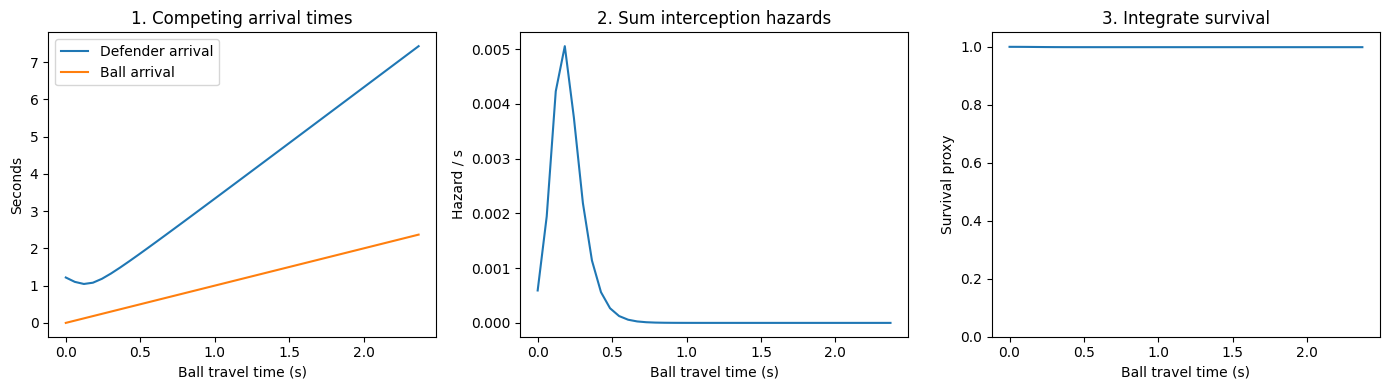

In [10]:
destination=options.loc[np.hypot(options.x-start[0],options.y-start[1]).idxmax(),['x','y']].to_numpy(dtype=float)
times,player_arrival,hazard,survival=interception_components(start,destination,positions[~home])
display(pd.DataFrame({'ball_time_s':times,'earliest_defender_arrival_s':player_arrival.min(axis=1),'total_hazard_per_s':hazard.sum(axis=1),'survival':survival}).head(10))
fig,axs=plt.subplots(1,3,figsize=(14,4))
axs[0].plot(times,player_arrival.min(axis=1),label='Defender arrival')
axs[0].plot(times,times,label='Ball arrival')
axs[0].legend()
axs[0].set(title='1. Competing arrival times',xlabel='Ball travel time (s)',ylabel='Seconds')
axs[1].plot(times,hazard.sum(axis=1))
axs[1].set(title='2. Sum interception hazards',xlabel='Ball travel time (s)',ylabel='Hazard / s')
axs[2].plot(times,survival)
axs[2].set(title='3. Integrate survival',xlabel='Ball travel time (s)',ylabel='Survival proxy',ylim=(0,1.05))
plt.tight_layout()
plt.show()

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
